<a href="https://colab.research.google.com/github/fereena-cathy/Deep-Learning/blob/main/DL_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

tf.random.set_seed(42)
np.random.seed(42)

In [2]:
#task A | Roll No: 24BAD024

# Load the IMDB dataset directly from Keras (already labelled 0 = negative, 1 = positive)
VOCAB_SIZE = 10000
MAX_LEN = 200

(x_train_raw, y_train), (x_test_raw, y_test) = tf.keras.datasets.imdb.load_data(num_words=VOCAB_SIZE)

print("Training samples:", len(x_train_raw))
print("Testing samples:", len(x_test_raw))

# Decode one review back to text just to look at it
word_index = tf.keras.datasets.imdb.get_word_index()
index_to_word = {v + 3: k for k, v in word_index.items()}
index_to_word[0], index_to_word[1], index_to_word[2] = "<PAD>", "<START>", "<UNK>"

def decode_review(seq):
    return " ".join(index_to_word.get(i, "?") for i in seq)

print("\nSample review (decoded):")
print(decode_review(x_train_raw[0]))
print("\nLabel (0 = negative, 1 = positive):", y_train[0])

# Positive vs negative class counts
unique, counts = np.unique(y_train, return_counts=True)
print("\nClass distribution in training set:", dict(zip(unique, counts)))

# Apply sequence padding so every review is the same length
x_train = pad_sequences(x_train_raw, maxlen=MAX_LEN, padding='post', truncating='post')
x_test = pad_sequences(x_test_raw, maxlen=MAX_LEN, padding='post', truncating='post')

# Split off a validation set from the training data
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.2, random_state=42)

print("\nFinal shapes:")
print("x_train:", x_train.shape, " x_val:", x_val.shape, " x_test:", x_test.shape)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Testing samples: 25000
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Sample review (decoded):
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were just brilliant children are often left out o

In [3]:
#task B | Roll No: 24BAD024

EMBED_DIM = 64
LSTM_UNITS = 64

model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM, input_length=MAX_LEN),
    LSTM(LSTM_UNITS),
    Dense(1, activation='sigmoid')   # sigmoid for binary sentiment classification
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 52s 161ms/step - accuracy: 0.5184 - loss: 0.6947 - val_accuracy: 0.5226 - val_loss: 0.6904
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 51s 163ms/step - accuracy: 0.5692 - loss: 0.6759 - val_accuracy: 0.5126 - val_loss: 0.6916
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 160ms/step - accuracy: 0.5780 - loss: 0.6689 - val_accuracy: 0.5146 - val_loss: 0.6931
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 50s 160ms/step - accuracy: 0.6033 - loss: 0.6470 - val_accuracy: 0.7080 - val_loss: 0.6261
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 50s 161ms/step - accuracy: 0.7406 - loss: 0.5492 - val_accuracy: 0.7594 - val_loss: 0.5486

Training accuracy:   0.7406499981880188
Validation accuracy: 0.7594000101089478
Training loss:       0.5491588115692139
Validation loss:     0.5486286878585815
782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 29ms/step

Test Accuracy : 0.7466
Test Precision: 0.7364
Test Recall   : 0.7682
Test F1-score : 0.7519

Confusion Matrix:
 [[9063 3437]
 [2898 9602]]


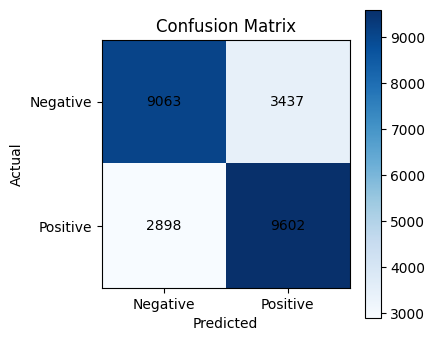

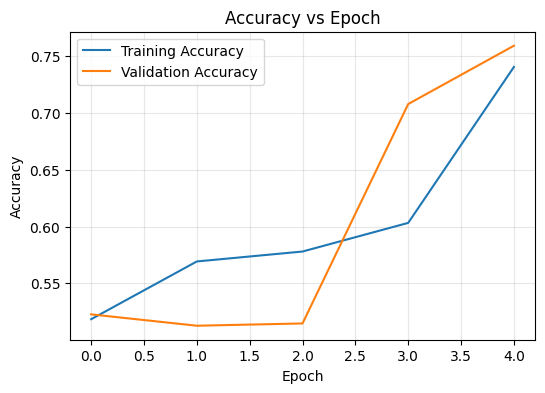

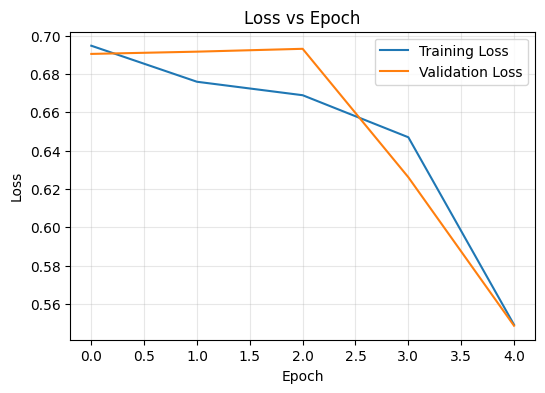

In [4]:
# task C | Roll No: 24BAD

EPOCHS = 5
BATCH_SIZE = 64

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

# Final recorded metrics
print("\nTraining accuracy:  ", history.history['accuracy'][-1])
print("Validation accuracy:", history.history['val_accuracy'][-1])
print("Training loss:      ", history.history['loss'][-1])
print("Validation loss:    ", history.history['val_loss'][-1])

# Evaluate on the held-out test set
y_prob = model.predict(x_test)
y_pred = (y_prob >= 0.5).astype(int).ravel()

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"\nTest Accuracy : {acc:.4f}")
print(f"Test Precision: {prec:.4f}")
print(f"Test Recall   : {rec:.4f}")
print(f"Test F1-score : {f1:.4f}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(4,4))
plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks([0,1], ["Negative","Positive"])
plt.yticks([0,1], ["Negative","Positive"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j], ha='center', va='center', color='black')
plt.colorbar()
plt.show()

# Accuracy vs Epoch
plt.figure(figsize=(6,4))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy vs Epoch')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

# Loss vs Epoch
plt.figure(figsize=(6,4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss vs Epoch')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [6]:
# task D | Roll No:24BAD024

def encode_review(text, word_index, max_len=MAX_LEN):
    words = text.lower().split()
    encoded = [1]  # <START> token
    for w in words:
        idx = word_index.get(w, 2) + 3  # 2 = <UNK>, offset by 3 like IMDB does
        if idx < VOCAB_SIZE:
            encoded.append(idx)
        else:
            encoded.append(2)
    return pad_sequences([encoded], maxlen=max_len, padding='post', truncating='post')

def predict_sentiment(text):
    seq = encode_review(text, word_index)
    prob = model.predict(seq, verbose=0)[0][0]
    label = "Positive" if prob >= 0.5 else "Negative"
    return label, prob

# A few new review samples with known/expected sentiment
test_reviews = [
    ("This movie was absolutely fantastic, the acting and story were great!", "Positive"),
    ("Terrible film, I wasted two hours of my life watching this garbage.", "Negative"),
    ("One of the best movies I have seen this year, truly inspiring.", "Positive"),
    ("The plot was boring and the characters were poorly written.", "Negative"),
    ("An average movie, nothing special but not bad either.", "Positive/Negative (ambiguous)"),
]

print(f"{'Review':60s} {'Predicted':10s} {'Prob':8s} {'Expected'}")
print("-"*100)
for review, expected in test_reviews:
    label, prob = predict_sentiment(review)
    print(f"{review[:57]+'...':60s} {label:10s} {prob:.4f}  {expected}")

Review                                                       Predicted  Prob     Expected
----------------------------------------------------------------------------------------------------
This movie was absolutely fantastic, the acting and story... Negative   0.2262  Positive
Terrible film, I wasted two hours of my life watching thi... Negative   0.2263  Negative
One of the best movies I have seen this year, truly inspi... Negative   0.2313  Positive
The plot was boring and the characters were poorly writte... Negative   0.2262  Negative
An average movie, nothing special but not bad either....     Negative   0.2262  Positive/Negative (ambiguous)
